# TouNum — Livrable 1 : classification binaire *photo / non-photo*

**Équipe Data Science CESI** · Prototype du workflow de catégorisation automatique d'images

---
## 0. Contexte métier et objectif

**TouNum** numérise des documents (textes, images…) pour le compte de ses clients et veut proposer un service de
**catégorisation et de légendage automatique** des images. Le workflow cible comporte trois modules :

1. **Tri** : ne garder que les *photographies* (ce livrable) ;
2. **Prétraitement** : nettoyer les images floues ou bruitées (livrable 2) ;
3. **Captioning** : générer une légende descriptive (livrable 3).

Or, parmi les images déjà numérisées, beaucoup **ne sont pas des photos** (schémas, textes scannés, dessins,
peintures). Les envoyer au module de légendage serait inutile et produirait des légendes absurdes.
**Ce notebook construit le filtre d'entrée** : un réseau de neurones qui répond « photo » (1) ou « autre » (0).

### Ce que ce notebook démontre
| Section | Contenu |
|---|---|
| 1 | Environnement et reproductibilité |
| 2 | Les données : inventaire, exploration, échantillonnage |
| 3 | Découpage train / validation / test |
| 4 | **Progression par difficulté** : texte → schémas → dessins → peintures |
| 5 | **Architecture du réseau** : schéma, paramètres, perte, optimiseur |
| 6 | **Entraînement** : courbes d'erreur et d'accuracy (train vs validation) |
| 7 | **Analyse biais / variance** (sous- et sur-apprentissage) |
| 8 | **Améliorations** : augmentation, dropout, L2, early stopping |
| 9 | Évaluation finale (test équilibré et test « réaliste »), erreurs, choix du seuil, mise en production |
| 10 | Comparaison avec un réseau pré-entraîné (MobileNetV2) |
| 11 | Conclusion, limites et suites |

### Comment relancer
`Kernel → Restart & Run All`. Les images sont extraites des archives et mises en cache dans `data/` à la première
exécution (quelques minutes), puis relues instantanément. `TOUNUM_QUICK=1` (variable d'environnement) lance une
version très courte (2 epochs) pour tester que tout s'exécute.

## 1. Environnement et reproductibilité

In [1]:
import os
import sys
import time
import inspect
from pathlib import Path

os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")      # moins de bruit TensorFlow
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))                   # le code réutilisable est dans src/tounum_cls

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
from IPython.display import display, Markdown
import tensorflow as tf
import keras
import sklearn

from tounum_cls import config, data, modeling, evaluation

QUICK = os.environ.get("TOUNUM_QUICK") == "1"
# Nombre d'epochs par expérience (réduit en mode QUICK)
EPOCHS = {"stage": 8, "main": 20, "curve": 12, "improve": 25, "mobilenet": 8}
if QUICK:
    EPOCHS = {k: 2 for k in EPOCHS}

keras.utils.set_random_seed(config.SEED)                # fixe les graines Python, NumPy et TensorFlow
pd.set_option("display.precision", 3)
pd.set_option("display.width", 140)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 100

print(f"Python {sys.version.split()[0]} | TensorFlow {tf.__version__} | Keras {keras.__version__} | "
      f"scikit-learn {sklearn.__version__} | pandas {pd.__version__} | numpy {np.__version__}")
print("GPU détecté :", tf.config.list_physical_devices("GPU") or "aucun (calcul sur CPU)")
print(f"Graine : {config.SEED} | mode QUICK : {QUICK} | epochs : {EPOCHS}")

I0000 00:00:1790888240.905258 2318141 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1790888240.905579 2318141 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


I0000 00:00:1790888241.554607 2318141 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1790888241.554823 2318141 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


Python 3.12.13 | TensorFlow 2.21.0 | Keras 3.15.1 | scikit-learn 1.9.1 | pandas 3.0.6 | numpy 2.5.3
GPU détecté : aucun (calcul sur CPU)
Graine : 42 | mode QUICK : False | epochs : {'stage': 8, 'main': 20, 'curve': 12, 'improve': 25, 'mobilenet': 8}


E0000 00:00:1790888241.811068 2318141 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


> **Reproductibilité.** Toutes les sources d'aléa (tirage des images, découpage, initialisation des poids,
> mélange des batchs) dépendent de la graine `SEED = 42`. Sur CPU, TensorFlow peut tout de même produire de très
> petites variations d'une exécution à l'autre (ordre des opérations parallèles) : les conclusions ne changent pas,
> mais les décimales peuvent bouger.

## 2. Les données

TouNum fournit cinq archives, **une par type d'image**. Le nom de l'archive est l'étiquette : il n'y a pas de fichier
d'annotations. Notre cible binaire est : `Photo` → **1**, tout le reste → **0**.

Les archives pèsent plusieurs Go. La fonction `prepare_dataset()` :
1. inventorie les images (extensions jpg/png ; on ignore par exemple le fichier parasite `desktop.ini`) ;
2. tire un échantillon **reproductible** et **disjoint** : un *pool de modélisation* équilibré et un *test étendu* ;
3. n'extrait que les fichiers tirés ;
4. les charge avec **ImageIO**, les convertit en **RGB** (les sketchs sont en niveaux de gris), les redimensionne en
   **128×128** et les stocke en `uint8` dans un cache (`data/cache`).

In [2]:
t0 = time.perf_counter()
X, meta = data.prepare_dataset()
print(f"X : {X.shape}, dtype={X.dtype}, {X.nbytes / 1e6:.0f} Mo en mémoire | chargé en {time.perf_counter() - t0:.0f} s")

summary = meta.groupby(["source", "subset"]).size().unstack(fill_value=0)
summary["total tiré"] = summary.sum(axis=1)
display(summary.loc[config.CLASSES])

X : (10806, 128, 128, 3), dtype=uint8, 531 Mo en mémoire | chargé en 16 s


subset,ext,pool,total tiré
source,,,
Photo,1000,3000,4000
Painting,1000,1200,2200
Schematics,1000,600,1600
Text,1000,600,1600
Sketch,806,600,1406


**Pourquoi un échantillon et pas les ~42 000 images ?** Nous calculons sur CPU. Un échantillon équilibré de
6 000 images (3 000 photos / 3 000 non-photos) suffit largement pour une tâche de ce type et permet de multiplier
les expériences (comparaisons, régularisation) en un temps raisonnable. Les effectifs sont réglables dans
`src/tounum_cls/config.py` (`POOL_COUNTS`, `EXT_COUNTS`).

- Le **pool** est équilibré 50/50 ; les peintures y sont sur-représentées (1 200) car c'est la classe la plus difficile.
- Le **test étendu** (`ext`) n'est **jamais** utilisé pour entraîner ni pour choisir un modèle. Il est *déséquilibré*
  (≈ 21 % de photos) pour estimer les performances sur un fonds documentaire réel.

### 2.1 Taille d'origine des images
Les images n'ont ni la même taille ni le même format. On lit uniquement l'en-tête des fichiers (rapide).

In [3]:
def original_size(path):
    with Image.open(path) as im:
        return im.size  # (largeur, hauteur)

sizes = meta["path"].map(original_size)
meta["width"] = [s[0] for s in sizes]
meta["height"] = [s[1] for s in sizes]
meta["megapixels"] = meta["width"] * meta["height"] / 1e6
display(meta.groupby("source")[["width", "height", "megapixels"]].median().loc[config.CLASSES])
print("Toutes les images sont ramenées à 128×128 (étirement, ratio non conservé) : les formes très allongées "
      "(pages de texte A4) sont déformées, ce qui est acceptable pour une simple décision photo / non-photo.")

,width,height,megapixels
source,,,
Photo,640.0,480.0,0.273
Painting,800.0,800.0,0.696
Schematics,679.0,461.5,0.314
Text,595.0,842.0,0.501
Sketch,1111.0,1111.0,1.234


Toutes les images sont ramenées à 128×128 (étirement, ratio non conservé) : les formes très allongées (pages de texte A4) sont déformées, ce qui est acceptable pour une simple décision photo / non-photo.


### 2.2 Aperçu visuel (images telles que vues par le réseau, 128×128)

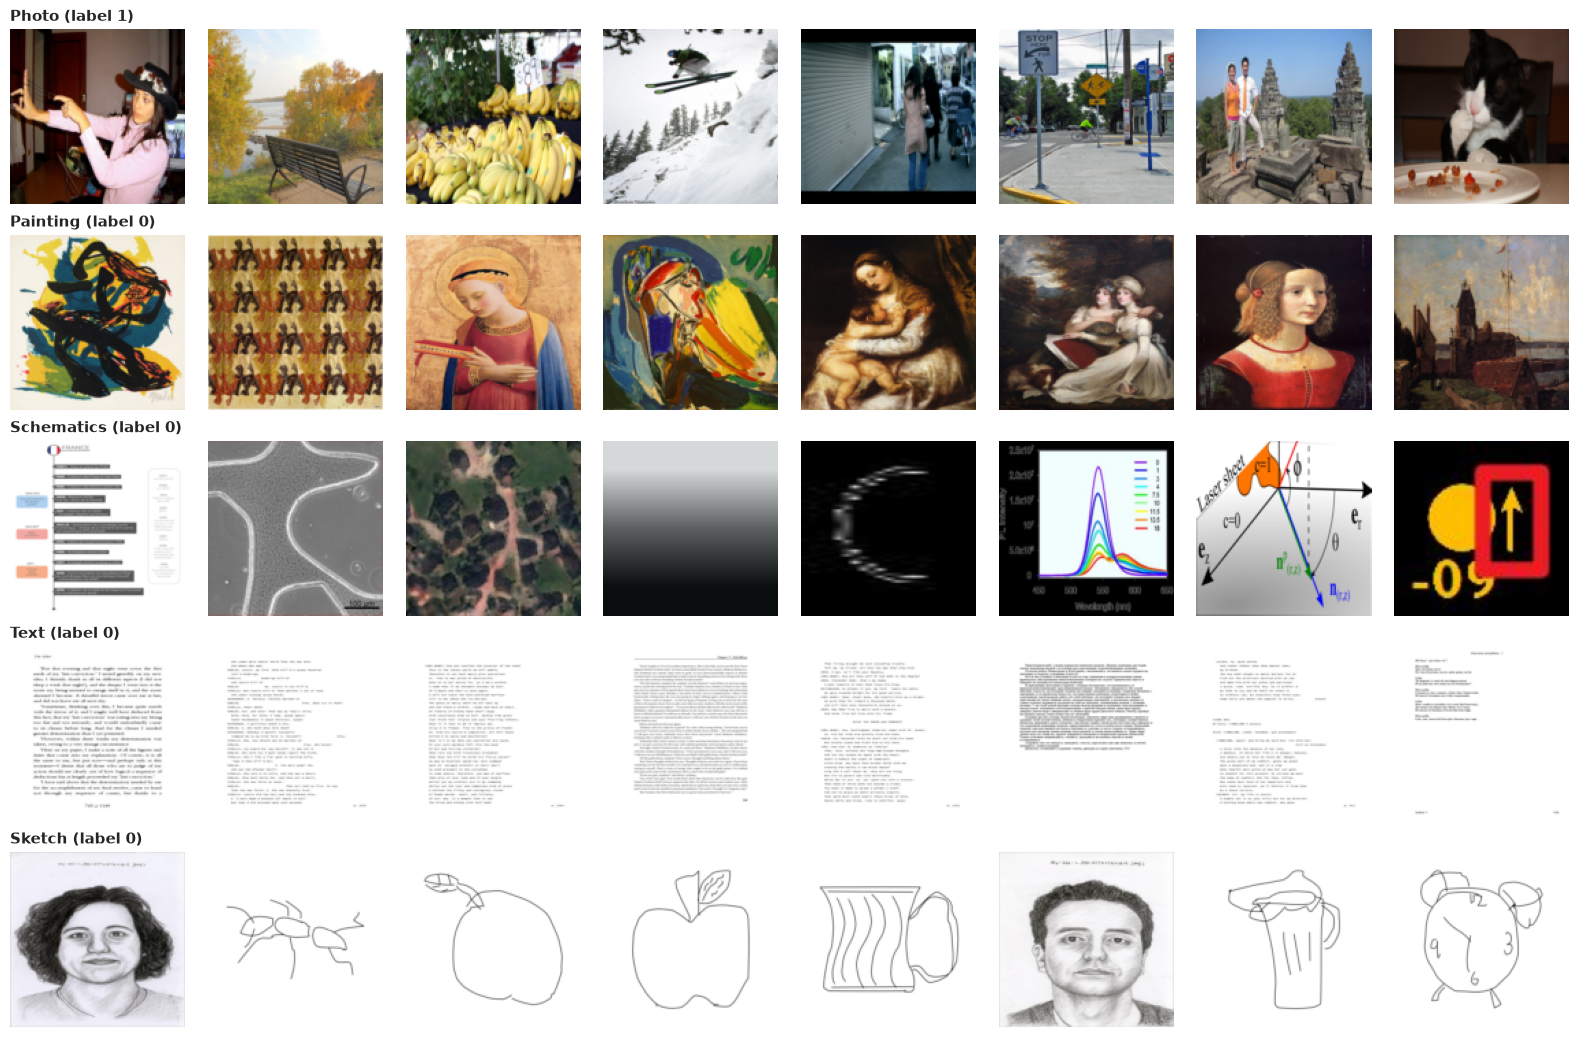

In [4]:
rng = np.random.default_rng(config.SEED)
fig, axes = plt.subplots(len(config.CLASSES), 8, figsize=(16, 2.1 * len(config.CLASSES)))
for r, source in enumerate(config.CLASSES):
    idx = rng.choice(meta.index[(meta["source"] == source) & (meta["subset"] == "pool")], 8, replace=False)
    for c, i in enumerate(idx):
        axes[r, c].imshow(X[i])
        axes[r, c].axis("off")
    axes[r, 0].set_title(source + (" (label 1)" if source == config.POSITIVE_CLASS else " (label 0)"),
                         loc="left", fontsize=11, fontweight="bold")
plt.tight_layout()
plt.show()

### 2.3 Statistiques simples : ce qui distingue déjà les classes
Deux descripteurs très simples : la **luminosité moyenne** et la **colorimétrie** (écart moyen entre canaux R, G, B :
0 pour une image en niveaux de gris). Ils donnent une intuition de la difficulté de chaque séparation.

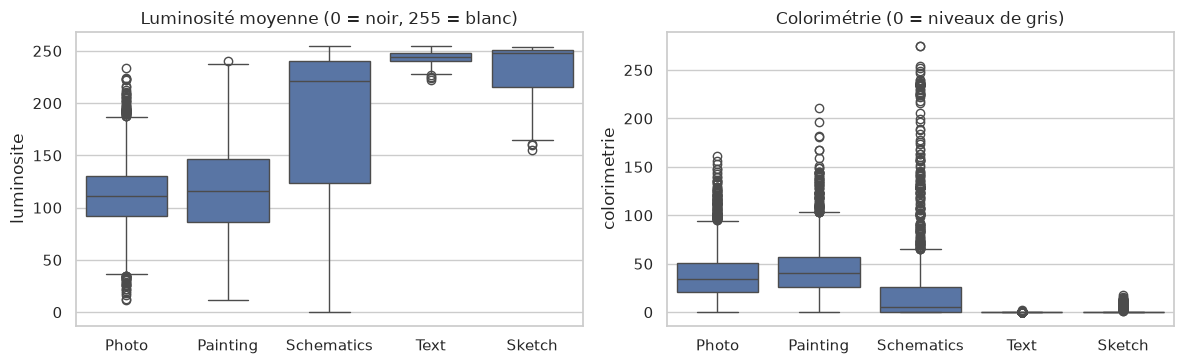

In [5]:
pix = X.astype(np.float32)
meta["luminosite"] = pix.mean(axis=(1, 2, 3))
meta["colorimetrie"] = (np.abs(pix[..., 0] - pix[..., 1]) + np.abs(pix[..., 1] - pix[..., 2])).mean(axis=(1, 2))
del pix

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
sns.boxplot(data=meta, x="source", y="luminosite", order=config.CLASSES, ax=axes[0])
axes[0].set_title("Luminosité moyenne (0 = noir, 255 = blanc)")
sns.boxplot(data=meta, x="source", y="colorimetrie", order=config.CLASSES, ax=axes[1])
axes[1].set_title("Colorimétrie (0 = niveaux de gris)")
for ax in axes:
    ax.set_xlabel("")
plt.tight_layout()
plt.show()

**Lecture.** Les textes scannés sont très clairs (luminosité ≈ 244) et sans aucune couleur, les sketchs sont clairs
(≈ 234) et en niveaux de gris, les schémas sont en général clairs mais très variables (certains sont sombres ou
colorés) : un classifieur très simple (seuils sur ces deux grandeurs) en séparerait déjà une bonne part.
En revanche, les **peintures** occupent les mêmes plages de luminosité (≈ 118 contre ≈ 112) et de couleur que les
photos : elles ne se distingueront que par la **texture et la structure** de l'image, que seul un réseau de
convolution peut exploiter. C'est pourquoi on avance par difficulté croissante (section 4).

## 3. Découpage train / validation / test

Le pool est découpé **de façon stratifiée par classe source** (et non seulement par label binaire), pour que chaque
type d'image soit représenté dans les mêmes proportions dans les trois ensembles :

| Ensemble | Part | Rôle |
|---|---|---|
| `train` | 70 % | apprendre les poids du réseau |
| `val` (validation) | 15 % | suivre l'apprentissage epoch par epoch, régler / choisir le modèle. **C'est « l'erreur de test » des courbes de la section 6** |
| `test` | 15 % | mesure finale, utilisée **une seule fois** à la fin (sections 4 et 9) |
| `ext` | — | test étendu déséquilibré, hors pool |

> Si l'on choisissait le modèle en regardant le jeu de test, on lui « fuiterait » de l'information et l'accuracy
> affichée serait trop optimiste. D'où la séparation validation / test.

In [6]:
split_table = pd.crosstab(meta["source"], meta["split"]).loc[config.CLASSES, ["train", "val", "test", "ext"]]
split_table.loc["TOTAL"] = split_table.sum()
display(split_table)

# garde-fou anti-fuite : aucun fichier ne doit apparaître dans deux ensembles
members = {s: set(meta.loc[meta["split"] == s, "member"]) for s in ["train", "val", "test", "ext"]}
for a in members:
    for b in members:
        if a < b:
            assert not (members[a] & members[b]), f"fuite de données entre {a} et {b}"
print("OK : les ensembles train / val / test / ext sont deux à deux disjoints.")

split,train,val,test,ext
source,,,,
Photo,2100,450,450,1000
Painting,840,180,180,1000
Schematics,420,90,90,1000
Text,420,90,90,1000
Sketch,420,90,90,806
TOTAL,4200,900,900,4806


OK : les ensembles train / val / test / ext sont deux à deux disjoints.


Fonctions utilitaires du notebook : récupérer les données d'une étape et lancer un entraînement chronométré.

In [7]:
def get_split(negative_sources=None):
    """{'train': (X, y, meta), 'val': ..., 'test': ...}. Les photos sont toujours incluses ;
    `negative_sources` choisit les classes négatives (None = toutes)."""
    return {s: data.select(X, meta, s, negative_sources) for s in ("train", "val", "test")}


def run(split, epochs, early_stopping=False, patience=4, **model_kwargs):
    """Construit un CNN (`model_kwargs` -> modeling.build_cnn), l'entraîne et renvoie (modèle, historique, secondes)."""
    keras.utils.set_random_seed(config.SEED)
    Xtr, ytr, _ = split["train"]
    Xva, yva, _ = split["val"]
    model = modeling.build_cnn(**model_kwargs)
    t0 = time.perf_counter()
    hist = modeling.train(
        model,
        data.make_dataset(Xtr, ytr, shuffle=True),
        data.make_dataset(Xva, yva),
        epochs=epochs,
        class_weight=data.class_weights(ytr),
        early_stopping=early_stopping,
        patience=patience,
        verbose=0,
    )
    return model, hist, time.perf_counter() - t0

## 4. Progression par difficulté

Le sujet recommande de commencer par les images les plus faciles à distinguer des photos. On entraîne donc **le même
réseau** (défini en section 5) sur quatre problèmes de difficulté croissante, en ajoutant à chaque étape un type
d'image « négatif » :

| Étape | Photos opposées à… |
|---|---|
| 1 | textes scannés |
| 2 | textes + schémas |
| 3 | textes + schémas + sketchs |
| 4 | **textes + schémas + sketchs + peintures** (problème final) |

Aux étapes 1 à 3, les photos sont plus nombreuses que les négatifs : on utilise des **poids de classe**
(`class_weight`) et, pour juger honnêtement, la **balanced accuracy** (moyenne du rappel sur chaque classe) plutôt que
l'accuracy brute. L'évaluation se fait sur le jeu `test` de l'étape (jamais vu à l'entraînement).

In [8]:
stage_rows, stage_per_source, stage_models = [], {}, {}
for stage, negatives in config.STAGES.items():
    split = get_split(negatives)
    model, hist, seconds = run(split, EPOCHS["stage"], early_stopping=True, patience=3)
    Xte, yte, mte = split["test"]
    proba = modeling.predict_proba(model, Xte)
    res = evaluation.evaluate_binary(yte, proba)
    per_src = evaluation.per_source_accuracy(mte, proba)
    worst = per_src.iloc[0]
    stage_rows.append({
        "étape": stage, "n_train": len(split["train"][1]), "epochs": len(hist), "durée (s)": round(seconds),
        "balanced_acc": res["balanced_accuracy"], "précision": res["precision"], "rappel": res["recall"],
        "F1": res["f1"], "ROC-AUC": res["roc_auc"], "classe la plus difficile": worst["source"],
        "accuracy sur cette classe": worst["accuracy"],
    })
    stage_per_source[stage] = per_src.set_index("source")["accuracy"]
    stage_models[stage] = model
stage_df = pd.DataFrame(stage_rows).set_index("étape")
display(stage_df)

,n_train,epochs,durée (s),balanced_acc,précision,rappel,F1,ROC-AUC,classe la plus difficile,accuracy sur cette classe
étape,,,,,,,,,,
1_photo_vs_text,2520,6,35,1.000,1.000,1.000,1.000,1.000,Photo,1.000
2_+schematics,2940,5,34,0.951,0.975,0.962,0.969,0.986,Schematics,0.878
3_+sketch,3360,8,61,0.975,0.978,0.987,0.982,0.995,Schematics,0.889
4_+painting,4200,6,57,0.878,0.874,0.882,0.878,0.947,Painting,0.717


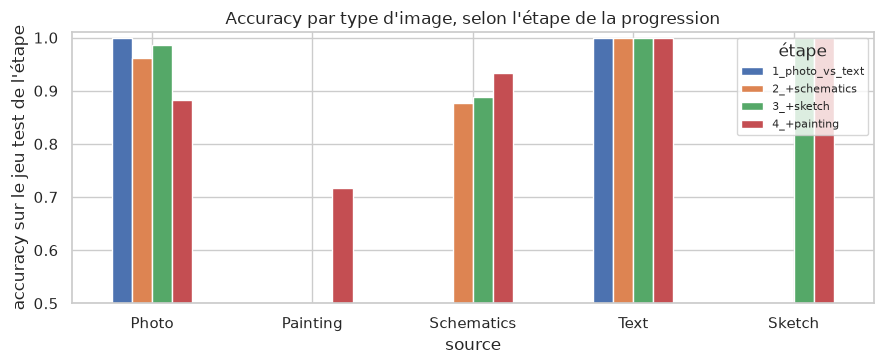

In [9]:
fig, ax = plt.subplots(figsize=(9, 3.8))
pd.DataFrame(stage_per_source).loc[config.CLASSES].plot.bar(ax=ax, rot=0)
ax.set_ylim(0.5, 1.01)
ax.set_ylabel("accuracy sur le jeu test de l'étape")
ax.set_title("Accuracy par type d'image, selon l'étape de la progression")
ax.legend(title="étape", fontsize=8)
plt.tight_layout()
plt.show()

In [10]:
last = stage_df.iloc[-1]
first = stage_df.iloc[0]
display(Markdown(
    f"**Lecture automatique.** Étape 1 (photo vs texte) : balanced accuracy **{first['balanced_acc']:.3f}** ; "
    f"étape 4 (toutes classes, peintures comprises) : **{last['balanced_acc']:.3f}**, F1 **{last['F1']:.3f}**. "
    f"À l'étape 4, la classe la plus difficile est **{last['classe la plus difficile']}** "
    f"(accuracy {last['accuracy sur cette classe']:.3f}). "
    + ("Conforme à l'attente : les peintures réalistes, visuellement proches des photos, concentrent les erreurs."
       if last["classe la plus difficile"] == "Painting"
       else "Contrairement à l'attente, ce ne sont pas les peintures qui posent le plus de problèmes : à analyser.")
))

**Lecture automatique.** Étape 1 (photo vs texte) : balanced accuracy **1.000** ; étape 4 (toutes classes, peintures comprises) : **0.878**, F1 **0.878**. À l'étape 4, la classe la plus difficile est **Painting** (accuracy 0.717). Conforme à l'attente : les peintures réalistes, visuellement proches des photos, concentrent les erreurs.

## 5. Architecture du réseau

On utilise un **réseau de neurones convolutif (CNN)** conçu pour ce problème. Le code ci-dessous est celui qui est
réellement utilisé dans tout le notebook (`src/tounum_cls/modeling.py`).

In [11]:
print(inspect.getsource(modeling._compile))   # perte, optimiseur, métriques
print(inspect.getsource(modeling.build_cnn))  # architecture

def _compile(model: keras.Model, learning_rate: float = 1e-3) -> keras.Model:
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=learning_rate),
        loss="binary_crossentropy",
        metrics=["accuracy", keras.metrics.AUC(name="auc")],
    )
    return model

def build_cnn(
    filters: tuple[int, ...] = (16, 32, 64, 128),
    dense_units: int = 64,
    dropout: float = 0.0,
    l2: float = 0.0,
    augmentation: bool = False,
    img_size: int = config.IMG_SIZE,
    learning_rate: float = 1e-3,
    bn_momentum: float = 0.9,
    name: str = "cnn_photo",
) -> keras.Model:
    """CNN « maison » pour photo (1) vs non-photo (0).

    Entrée : images uint8 (img_size, img_size, 3) ; la normalisation /255 est DANS le modèle.
    Un bloc = Conv2D 3x3 (padding same) -> BatchNormalization -> ReLU -> MaxPooling2D 2x2.
    Tête : GlobalAveragePooling2D -> Dense(dense_units, relu) -> [Dropout] -> Dense(1, sigmoid).
    `augmentation=True` ajoute des transformations aléat

In [12]:
baseline = modeling.build_cnn()
baseline.summary()

Model: "cnn_photo"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ image (InputLayer)              │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1 (Conv2D)                  │ (None, 128, 128, 16)   │           432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn1 (BatchNormalization)        │ (None, 128, 128, 16)   │            64 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu1 (Activation)              │ (None, 128, 128, 16)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool1 (MaxPooling2D)            │ (None, 64, 64, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2 (Conv2D)                  │ (None, 64, 64, 32)     │         4,608 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn2 (BatchNormalization)        │ (None, 64, 64, 32)     │           128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu2 (Activation)              │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool2 (MaxPooling2D)            │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv3 (Conv2D)                  │ (None, 32, 32, 64)     │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn3 (BatchNormalization)        │ (None, 32, 32, 64)     │           256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu3 (Activation)              │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool3 (MaxPooling2D)            │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv4 (Conv2D)                  │ (None, 16, 16, 128)    │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn4 (BatchNormalization)        │ (None, 16, 16, 128)    │           512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu4 (Activation)              │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool4 (MaxPooling2D)            │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gap (GlobalAveragePooling2D)    │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output (Dense)                  │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 106,481 (415.94 KB)

 Trainable params: 106,001 (414.07 KB)

 Non-trainable params: 480 (1.88 KB)

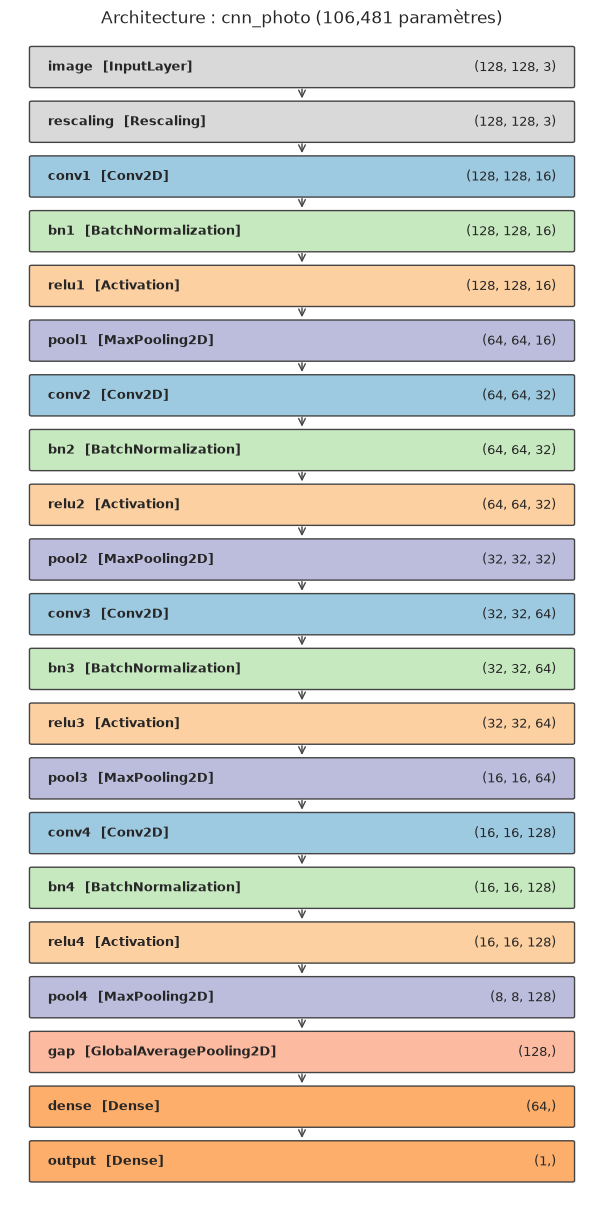

In [13]:
fig = evaluation.draw_architecture(baseline)
plt.show()

### 5.1 Rôle de chaque couche

| Couche | Rôle |
|---|---|
| `Rescaling(1/255)` | ramène les pixels de [0, 255] à [0, 1] (dans le modèle : l'inférence en production reçoit des images brutes) |
| `Conv2D 3×3` ×4 (16→32→64→128 filtres) | détecte des motifs locaux : bords et textures (premiers blocs), formes plus complexes (derniers blocs). Les filtres sont **appris**, comme les filtres de convolution du livrable 2 mais sans les fixer à la main |
| `BatchNormalization` | normalise les activations de chaque batch : apprentissage plus rapide et plus stable |
| `ReLU` | non-linéarité `max(0, x)` |
| `MaxPooling2D 2×2` | divise la résolution par 2 : moins de calculs, tolérance aux petits décalages |
| `GlobalAveragePooling2D` | moyenne chaque carte de caractéristiques en un seul nombre : évite une énorme couche dense (donc peu de paramètres, moins de sur-apprentissage) |
| `Dense(64, ReLU)` | combine les 128 caractéristiques |
| `Dense(1, sigmoïde)` | sortie : probabilité *P(photo)* ∈ [0, 1] |

### 5.2 Paramètres du réseau

In [14]:
rows = []
for layer in baseline.layers:
    rows.append({
        "couche": layer.name, "type": type(layer).__name__,
        "forme de sortie": str(tuple(layer.output.shape)[1:]), "paramètres": layer.count_params(),
    })
param_table = pd.DataFrame(rows)
display(param_table[param_table["paramètres"] > 0])
trainable = int(sum(np.prod(w.shape) for w in baseline.trainable_weights))
non_trainable = int(sum(np.prod(w.shape) for w in baseline.non_trainable_weights))
print(f"Total : {baseline.count_params():,} paramètres — entraînables : {trainable:,} — "
      f"non entraînables (moyennes/variances de BatchNorm) : {non_trainable:,}")

,couche,type,forme de sortie,paramètres
2,conv1,Conv2D,"(128, 128, 16)",432
3,bn1,BatchNormalization,"(128, 128, 16)",64
6,conv2,Conv2D,"(64, 64, 32)",4608
7,bn2,BatchNormalization,"(64, 64, 32)",128
10,conv3,Conv2D,"(32, 32, 64)",18432
11,bn3,BatchNormalization,"(32, 32, 64)",256
14,conv4,Conv2D,"(16, 16, 128)",73728
15,bn4,BatchNormalization,"(16, 16, 128)",512
19,dense,Dense,"(64,)",8256
20,output,Dense,"(1,)",65


Total : 106,481 paramètres — entraînables : 106,001 — non entraînables (moyennes/variances de BatchNorm) : 480


### 5.3 Fonction de perte

Sortie binaire → **entropie croisée binaire** (*binary cross-entropy*). Pour une image de label réel $y \in \{0, 1\}$
et une probabilité prédite $\hat{p}$ = P(photo) :

$$\mathcal{L}(y, \hat{p}) = -\big[\, y \log \hat{p} + (1 - y)\log(1 - \hat{p}) \,\big]$$

La perte est la moyenne sur le batch. Elle est faible quand le réseau est à la fois **juste et confiant**, et très
élevée quand il est **confiant et faux** (une peinture annoncée « photo » à 99 %). C'est la fonction naturelle d'une
sortie sigmoïde (maximum de vraisemblance d'une loi de Bernoulli) et elle donne de bons gradients, contrairement à
l'erreur quadratique.

### 5.4 Algorithme d'optimisation

**Adam** (taux d'apprentissage $10^{-3}$, $\beta_1 = 0{,}9$, $\beta_2 = 0{,}999$). Adam est une descente de gradient
stochastique par mini-batchs de 64 images, qui adapte le pas de chaque paramètre à partir d'une moyenne mobile du
gradient (inertie) et de son carré (échelle). C'est un choix par défaut robuste : il converge vite sans réglage
fin du pas. Les métriques suivies sont l'**accuracy** (part d'images bien classées au seuil 0,5) et l'**AUC**
(capacité à mieux classer une photo qu'une non-photo, indépendamment du seuil).

### 5.5 Pourquoi ce choix d'architecture ?
- **CNN plutôt que réseau dense** : le partage des filtres exploite la structure 2D de l'image avec très peu de
  paramètres (≈ 106 k, contre des millions pour un réseau dense sur 128×128×3 pixels).
- **Petit réseau** : la tâche est une décision globale simple, et nous calculons sur CPU.
- **Justification par les résultats** : sections 7 (le modèle n'est ni trop simple ni trop complexe), 8 et 10
  (comparaison avec un réseau pré-entraîné bien plus gros).

## 6. Entraînement et courbes d'apprentissage

Entraînement du modèle de référence (*baseline*, sans régularisation) sur le problème **final** (étape 4 : photos
contre toutes les autres classes). Les courbes comparent, à chaque epoch, l'**entraînement** et la **validation**
(« erreur de test » du sujet) pour la perte et pour l'accuracy.

In [15]:
FINAL_SPLIT = get_split(None)
Xtr, ytr, mtr = FINAL_SPLIT["train"]
Xva, yva, mva = FINAL_SPLIT["val"]
Xte, yte, mte = FINAL_SPLIT["test"]
print(f"train {Xtr.shape[0]} | val {Xva.shape[0]} | test {Xte.shape[0]} | part de photos dans train : {ytr.mean():.1%}")

baseline_model, baseline_hist, baseline_sec = run(FINAL_SPLIT, EPOCHS["main"])
print(f"Entraînement terminé en {baseline_sec:.0f} s ({baseline_sec / len(baseline_hist):.1f} s/epoch)")
shown = sorted({i for i in (0, 1, 2, len(baseline_hist) // 2, len(baseline_hist) - 1) if i < len(baseline_hist)})
display(baseline_hist.round(4).set_index("epoch").iloc[shown])

train 4200 | val 900 | test 900 | part de photos dans train : 50.0%


Entraînement terminé en 188 s (9.4 s/epoch)


,accuracy,auc,loss,val_accuracy,val_auc,val_loss
epoch,,,,,,
1,0.803,0.878,0.414,0.809,0.908,0.418
2,0.841,0.922,0.344,0.808,0.909,0.452
3,0.863,0.940,0.307,0.848,0.931,0.330
11,0.900,0.965,0.239,0.876,0.943,0.321
20,0.924,0.978,0.188,0.893,0.951,0.310


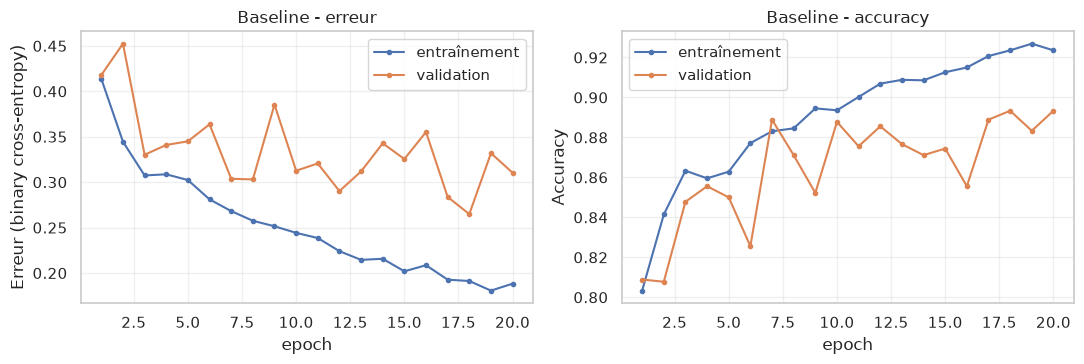

In [16]:
evaluation.plot_history(baseline_hist, "Baseline")
plt.show()

In [17]:
diag = evaluation.diagnose_fit(baseline_hist)
display(Markdown(
    f"**Lecture automatique (baseline).** Accuracy finale : entraînement **{diag['train_acc']:.3f}**, "
    f"validation **{diag['val_acc']:.3f}** (écart {diag['gap_acc']:+.3f}). "
    f"Perte finale : entraînement {diag['train_loss']:.3f}, validation {diag['val_loss']:.3f}. "
    f"Meilleure perte de validation à l'epoch **{diag['best_epoch']}** sur {len(baseline_hist)} "
    f"(remontée depuis ce minimum : {diag['val_loss_drift']:+.3f}). Diagnostic : **{diag['verdict']}**."
))

**Lecture automatique (baseline).** Accuracy finale : entraînement **0.924**, validation **0.893** (écart +0.030). Perte finale : entraînement 0.188, validation 0.310. Meilleure perte de validation à l'epoch **18** sur 20 (remontée depuis ce minimum : +0.045). Diagnostic : **compromis biais/variance correct**.

**Comment lire ces courbes.**
- Les premières epochs : la validation peut être instable (voire très mauvaise) car `BatchNormalization` utilise
  des statistiques mobiles qui mettent quelques pas à se calibrer. Ce n'est pas un défaut du modèle.
- Si la perte d'entraînement continue de baisser alors que celle de validation remonte, le réseau **mémorise**
  (sur-apprentissage).
- Si les deux courbes stagnent haut, le réseau est **trop simple** ou insuffisamment entraîné (sous-apprentissage).

## 7. Analyse du compromis biais / variance

**Rappel.**
- **Biais élevé = sous-apprentissage** : le modèle est trop rigide pour capturer la structure des données ; l'erreur est
  élevée *à la fois* sur l'entraînement et sur la validation.
- **Variance élevée = sur-apprentissage** : le modèle s'adapte au bruit des données d'entraînement ; l'erreur
  d'entraînement est faible mais celle de validation est nettement plus haute (grand écart).
- L'objectif est le bon compromis : les deux erreurs sont basses et proches.

Un modèle plus **complexe** réduit le biais mais augmente la variance. Nous le vérifions de deux façons.

### 7.1 Trois niveaux de capacité du modèle
Même données, même procédure ; seule la taille du réseau change.

In [18]:
CAPACITY = {
    "trop simple": dict(filters=(4, 8), dense_units=4),
    "baseline": dict(),
    "trop complexe": dict(filters=(32, 64, 128, 256), dense_units=256),
}
cap_hist, cap_models, cap_rows = {"baseline": baseline_hist}, {"baseline": baseline_model}, []
for name, kwargs in CAPACITY.items():
    if name == "baseline":
        model, hist, sec = baseline_model, baseline_hist, baseline_sec
    else:
        model, hist, sec = run(FINAL_SPLIT, EPOCHS["main"], **kwargs)
        cap_hist[name], cap_models[name] = hist, model
    d = evaluation.diagnose_fit(hist)
    cap_rows.append({"modèle": name, "paramètres": model.count_params(), "acc train": d["train_acc"],
                     "acc val": d["val_acc"], "écart": d["gap_acc"], "loss val min": hist["val_loss"].min(),
                     "epoch du min": d["best_epoch"], "diagnostic": d["verdict"]})
cap_df = pd.DataFrame(cap_rows).set_index("modèle")
display(cap_df)

,paramètres,acc train,acc val,écart,loss val min,epoch du min,diagnostic
modèle,,,,,,,
trop simple,485,0.787,0.776,0.011,0.435,20,biais élevé (sous-apprentissage)
baseline,106481,0.924,0.893,0.030,0.265,18,compromis biais/variance correct
trop complexe,455905,0.920,0.889,0.032,0.241,18,variance élevée (sur-apprentissage)


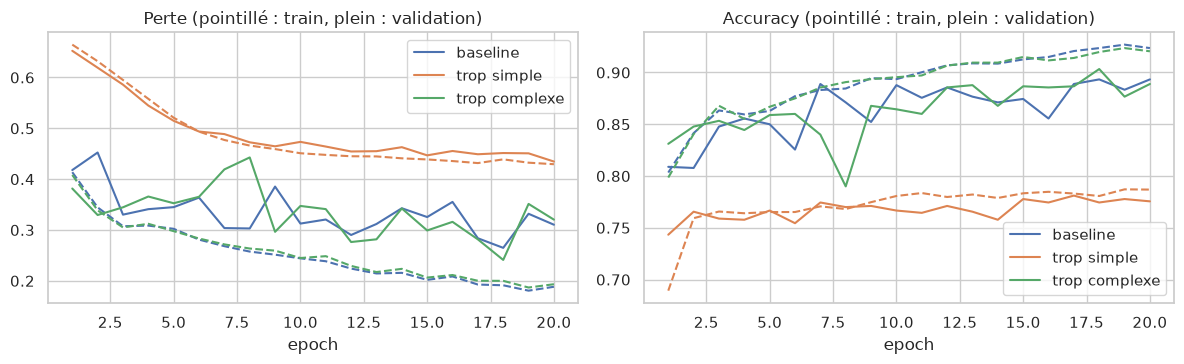

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for name, hist in cap_hist.items():
    line, = axes[0].plot(hist["epoch"], hist["loss"], ls="--")
    axes[0].plot(hist["epoch"], hist["val_loss"], color=line.get_color(), label=name)
    line, = axes[1].plot(hist["epoch"], hist["accuracy"], ls="--")
    axes[1].plot(hist["epoch"], hist["val_accuracy"], color=line.get_color(), label=name)
axes[0].set_title("Perte (pointillé : train, plein : validation)")
axes[1].set_title("Accuracy (pointillé : train, plein : validation)")
for ax in axes:
    ax.set_xlabel("epoch")
    ax.legend()
plt.tight_layout()
plt.show()

### 7.2 Courbe d'apprentissage : que se passe-t-il avec plus de données ?
On entraîne la baseline sur une fraction croissante du jeu d'entraînement (stratifiée par classe) et on compare
l'accuracy finale d'entraînement et de validation. Un **grand écart qui se resserre avec plus de données**
est le signe d'une variance qu'on peut réduire en collectant des images ; deux courbes **proches mais basses** signalent
un biais que plus de données ne corrigera pas.

,n_train,acc train,acc val
fraction,,,
0.10,420,0.898,0.780
0.25,1050,0.895,0.846
0.50,2100,0.902,0.857
1.00,4200,0.907,0.886


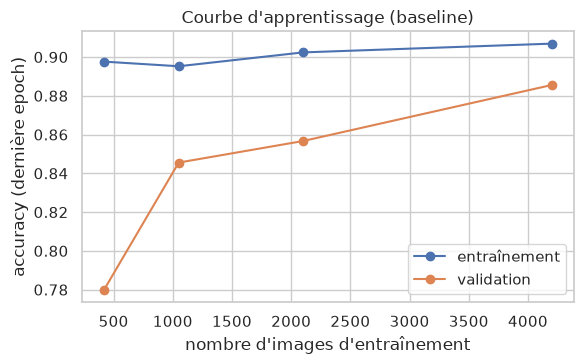

In [20]:
from sklearn.model_selection import train_test_split

curve_rows = []
for frac in (0.1, 0.25, 0.5, 1.0):
    if frac < 1.0:
        keep, _ = train_test_split(np.arange(len(ytr)), train_size=frac, stratify=mtr["source"], random_state=config.SEED)
    else:
        keep = np.arange(len(ytr))
    sub = {"train": (Xtr[keep], ytr[keep], mtr.iloc[keep]), "val": FINAL_SPLIT["val"], "test": FINAL_SPLIT["test"]}
    _, hist, _ = run(sub, EPOCHS["curve"])
    d = evaluation.diagnose_fit(hist)
    curve_rows.append({"fraction": frac, "n_train": len(keep), "acc train": d["train_acc"], "acc val": d["val_acc"]})
curve_df = pd.DataFrame(curve_rows).set_index("fraction")
display(curve_df)

fig, ax = plt.subplots(figsize=(6, 3.8))
ax.plot(curve_df["n_train"], curve_df["acc train"], marker="o", label="entraînement")
ax.plot(curve_df["n_train"], curve_df["acc val"], marker="o", label="validation")
ax.set_xlabel("nombre d'images d'entraînement")
ax.set_ylabel("accuracy (dernière epoch)")
ax.set_title("Courbe d'apprentissage (baseline)")
ax.legend()
plt.tight_layout()
plt.show()

In [21]:
small, big = curve_df.iloc[0], curve_df.iloc[-1]
display(Markdown(
    "**Lecture automatique.** "
    f"Capacité : le modèle « trop simple » ({cap_df.loc['trop simple', 'paramètres']:,} paramètres) atteint "
    f"{cap_df.loc['trop simple', 'acc val']:.3f} en validation, la baseline ({cap_df.loc['baseline', 'paramètres']:,}) "
    f"{cap_df.loc['baseline', 'acc val']:.3f} et le modèle « trop complexe » "
    f"({cap_df.loc['trop complexe', 'paramètres']:,}) {cap_df.loc['trop complexe', 'acc val']:.3f}. "
    f"Diagnostics : trop simple → *{cap_df.loc['trop simple', 'diagnostic']}* ; baseline → "
    f"*{cap_df.loc['baseline', 'diagnostic']}* ; trop complexe → *{cap_df.loc['trop complexe', 'diagnostic']}*. "
    f"Courbe d'apprentissage : avec {int(small['n_train'])} images, l'écart train − validation est "
    f"{small['acc train'] - small['acc val']:+.3f} ; avec {int(big['n_train'])} images, il est "
    f"{big['acc train'] - big['acc val']:+.3f}."
))

**Lecture automatique.** Capacité : le modèle « trop simple » (485 paramètres) atteint 0.776 en validation, la baseline (106,481) 0.893 et le modèle « trop complexe » (455,905) 0.889. Diagnostics : trop simple → *biais élevé (sous-apprentissage)* ; baseline → *compromis biais/variance correct* ; trop complexe → *variance élevée (sur-apprentissage)*. Courbe d'apprentissage : avec 420 images, l'écart train − validation est +0.118 ; avec 4200 images, il est +0.021.

**Interprétation.** Un écart qui se réduit quand le nombre d'images augmente montre que l'on est dans un
régime de **variance** : plus de données (ou une régularisation) aident. Un modèle dont l'accuracy d'entraînement
elle-même est insuffisante est dans un régime de **biais** : il faut alors plus de capacité ou plus d'epochs, pas
plus de données. Les valeurs affichées ci-dessus indiquent dans quel régime se trouve chaque configuration.
La baseline retenue est un compromis : assez de paramètres (≈ 106 k) pour séparer les photos des peintures, sans
la capacité excessive du gros modèle. Les techniques de la section suivante réduisent encore la variance.

## 8. Améliorer le compromis biais / variance

### 8.1 Les méthodes disponibles

| Méthode | Principe | Effet attendu | Dans ce notebook |
|---|---|---|---|
| **Plus de données** | davantage d'exemples = moins de mémorisation | ↓ variance | limité à l'échantillon (voir 7.2) |
| **Augmentation de données** | transformations aléatoires (flip, rotation, zoom, contraste) à chaque epoch : le réseau ne voit jamais deux fois exactement la même image | ↓ variance | oui |
| **Dropout** | éteint aléatoirement une fraction des neurones à chaque pas : empêche les co-adaptations | ↓ variance | oui (0,4) |
| **Régularisation L2** (*weight decay*) | ajoute $\lambda \sum w^2$ à la perte : pénalise les gros poids, lisse le modèle | ↓ variance | oui ($\lambda = 10^{-4}$) |
| **Early stopping** | arrête l'entraînement quand la perte de validation cesse de s'améliorer et restaure les meilleurs poids | ↓ variance | oui (patience 5) |
| **Réduire la capacité** | moins de couches / de filtres | ↓ variance, ↑ biais | cf. 7.1 |
| **BatchNormalization** | normalise les activations ; effet régularisant léger | stabilité | déjà dans le réseau |
| **Plus de capacité / plus d'epochs** | plus de filtres, apprentissage plus long | ↓ biais | cf. 7.1 |
| **Taux d'apprentissage adaptatif** | réduire le pas quand la validation stagne (`ReduceLROnPlateau`) | convergence plus fine | non retenu |
| **Transfert d'apprentissage** | partir d'un réseau pré-entraîné (ImageNet) | ↓ biais et variance avec peu de données | section 10 |

### 8.2 Expériences
Même problème (étape 4), même graine. On compare chaque technique **seule**, puis **combinées avec early stopping**.
L'early stopping est évalué avec un budget d'epochs plus large (il choisira lui-même quand s'arrêter).

In [22]:
IMPROVEMENTS = {
    "baseline": dict(kwargs=dict(), epochs=EPOCHS["main"], es=False),
    "+ augmentation": dict(kwargs=dict(augmentation=True), epochs=EPOCHS["main"], es=False),
    "+ dropout 0,4": dict(kwargs=dict(dropout=0.4), epochs=EPOCHS["main"], es=False),
    "+ L2 1e-4": dict(kwargs=dict(l2=1e-4), epochs=EPOCHS["main"], es=False),
    "+ early stopping": dict(kwargs=dict(), epochs=EPOCHS["improve"], es=True),
    "tout combiné": dict(kwargs=dict(augmentation=True, dropout=0.4, l2=1e-4), epochs=EPOCHS["improve"], es=True),
}
imp_hist, imp_models, imp_rows = {}, {}, []
for name, cfg in IMPROVEMENTS.items():
    if name == "baseline":
        model, hist, sec = baseline_model, baseline_hist, baseline_sec
    else:
        model, hist, sec = run(FINAL_SPLIT, cfg["epochs"], early_stopping=cfg["es"], patience=5, **cfg["kwargs"])
    imp_hist[name], imp_models[name] = hist, model
    d = evaluation.diagnose_fit(hist)
    val_metrics = model.evaluate(data.make_dataset(Xva, yva), verbose=0, return_dict=True)  # poids FINAUX du modèle
    imp_rows.append({"configuration": name, "epochs faits": len(hist), "acc train": d["train_acc"],
                     "écart train−val": d["gap_acc"], "loss val (modèle final)": val_metrics["loss"],
                     "acc val (modèle final)": val_metrics["accuracy"], "diagnostic": d["verdict"],
                     "durée (s)": round(sec)})
imp_df = pd.DataFrame(imp_rows).set_index("configuration")
display(imp_df)

,epochs faits,acc train,écart train−val,loss val (modèle final),acc val (modèle final),diagnostic,durée (s)
configuration,,,,,,,
baseline,20,0.924,0.030,0.310,0.893,compromis biais/variance correct,188
+ augmentation,20,0.905,0.026,0.320,0.879,compromis biais/variance correct,207
"+ dropout 0,4",20,0.914,0.037,0.404,0.877,variance élevée (sur-apprentissage),187
+ L2 1e-4,20,0.920,0.030,0.379,0.890,compromis biais/variance correct,187
+ early stopping,23,0.939,0.072,0.265,0.893,variance élevée (sur-apprentissage),215
tout combiné,13,0.868,0.053,0.345,0.850,biais élevé (sous-apprentissage),135


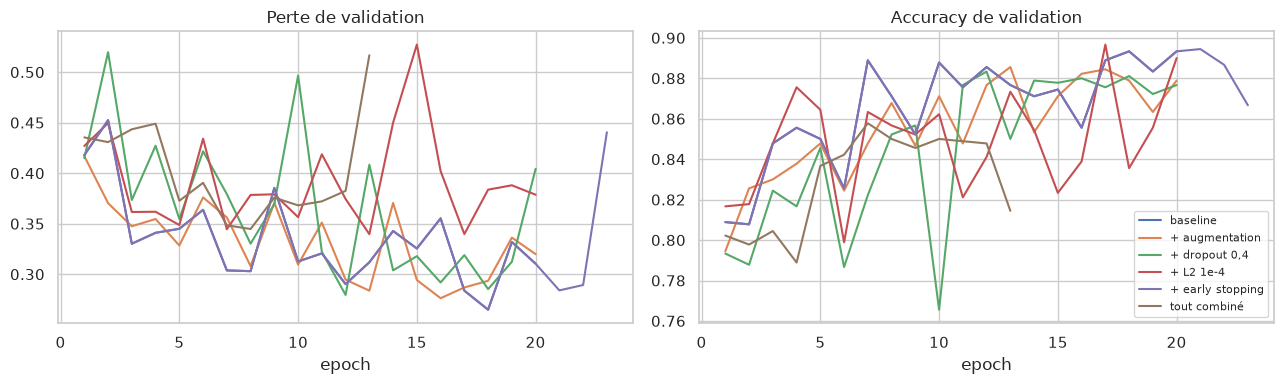

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for name, hist in imp_hist.items():
    axes[0].plot(hist["epoch"], hist["val_loss"], label=name)
    axes[1].plot(hist["epoch"], hist["val_accuracy"], label=name)
axes[0].set_title("Perte de validation")
axes[1].set_title("Accuracy de validation")
for ax in axes:
    ax.set_xlabel("epoch")
axes[0].set_ylim(top=min(1.5, axes[0].get_ylim()[1]))
axes[1].legend(fontsize=8)
plt.tight_layout()
plt.show()

In [24]:
best_name = imp_df["loss val (modèle final)"].idxmin()
display(Markdown(
    f"**Sélection du modèle (sur la validation uniquement).** La configuration avec la plus faible perte de validation "
    f"est **« {best_name} »** (loss {imp_df.loc[best_name, 'loss val (modèle final)']:.4f}, "
    f"accuracy {imp_df.loc[best_name, 'acc val (modèle final)']:.3f}) ; la baseline obtient "
    f"{imp_df.loc['baseline', 'loss val (modèle final)']:.4f} / {imp_df.loc['baseline', 'acc val (modèle final)']:.3f}. "
    "Ce modèle est celui évalué sur le jeu de test à la section suivante."
))
final_model = imp_models[best_name]
final_hist = imp_hist[best_name]

**Sélection du modèle (sur la validation uniquement).** La configuration avec la plus faible perte de validation est **« + early stopping »** (loss 0.2649, accuracy 0.893) ; la baseline obtient 0.3104 / 0.893. Ce modèle est celui évalué sur le jeu de test à la section suivante.

**Courbes du modèle retenu** (entraînement vs validation, pour la perte et l'accuracy) :

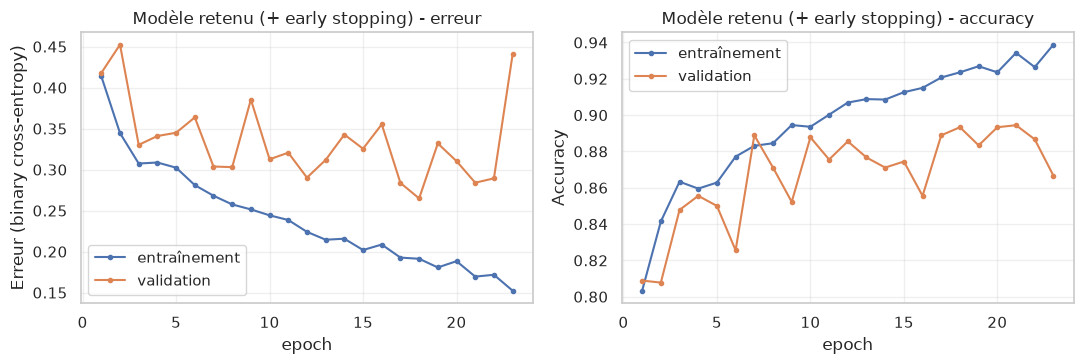

Diagnostic du modèle retenu : accuracy entraînement 0.939, validation 0.867, → **variance élevée (sur-apprentissage)**. Rappel : avec dropout et augmentation, l'accuracy d'entraînement est mesurée *avec* ces perturbations actives, donc plus basse que ce qu'elle serait en inférence.

In [25]:
evaluation.plot_history(final_hist, f"Modèle retenu ({best_name})")
plt.show()
d = evaluation.diagnose_fit(final_hist)
display(Markdown(
    f"Diagnostic du modèle retenu : accuracy entraînement {d['train_acc']:.3f}, validation {d['val_acc']:.3f}, "
    f"→ **{d['verdict']}**. Rappel : avec dropout et augmentation, l'accuracy d'entraînement est mesurée *avec* ces "
    "perturbations actives, donc plus basse que ce qu'elle serait en inférence."
))

## 9. Évaluation finale

On utilise maintenant le jeu **`test`** (équilibré, jamais vu) et le **test étendu `ext`** (déséquilibré, réaliste),
**une seule fois**, avec le modèle retenu en section 8.

In [26]:
Xe, ye, me = data.select(X, meta, "ext")
results, probas = {}, {}
for label, (Xs, ys, ms) in {"test (équilibré)": (Xte, yte, mte), "ext (réaliste)": (Xe, ye, me)}.items():
    probas[label] = modeling.predict_proba(final_model, Xs)
    results[label] = evaluation.evaluate_binary(ys, probas[label])
res_df = pd.DataFrame(results).T
display(res_df[["accuracy", "balanced_accuracy", "precision", "recall", "f1", "roc_auc", "tp", "fp", "fn", "tn"]])
print(f"Part de photos : test {yte.mean():.1%} | ext {ye.mean():.1%}")

,accuracy,balanced_accuracy,precision,recall,f1,roc_auc,tp,fp,fn,tn
test (équilibré),0.909,0.909,0.924,0.891,0.907,0.971,401.0,33.0,49.0,417.0
ext (réaliste),0.917,0.904,0.758,0.881,0.815,0.968,881.0,281.0,119.0,3525.0


Part de photos : test 50.0% | ext 20.8%


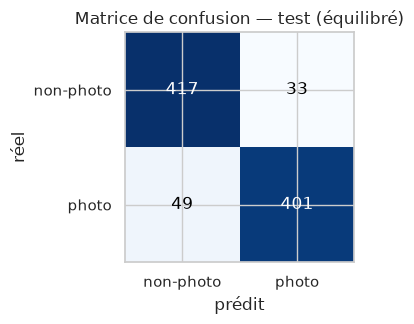

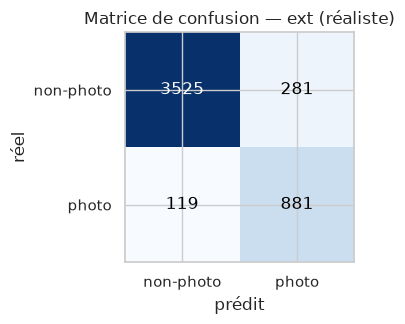

In [27]:
for label, (Xs, ys, ms) in {"test (équilibré)": (Xte, yte, mte), "ext (réaliste)": (Xe, ye, me)}.items():
    evaluation.plot_confusion(ys, probas[label], title=f"Matrice de confusion — {label}")
    plt.show()

### 9.1 Où le modèle se trompe-t-il ?
Accuracy par type d'image (sur le test étendu, plus large) :

,source,n,accuracy
0,Painting,1000,0.824
1,Photo,1000,0.881
2,Schematics,1000,0.896
3,Sketch,806,0.999
4,Text,1000,1.000


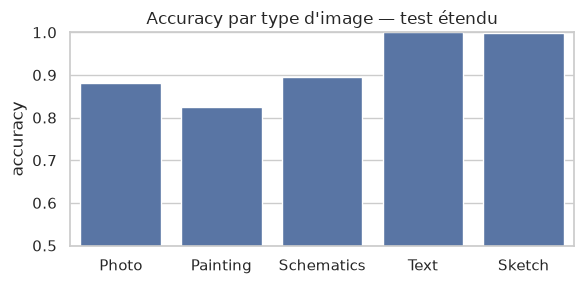

In [28]:
per_src_ext = evaluation.per_source_accuracy(me, probas["ext (réaliste)"])
display(per_src_ext)
fig, ax = plt.subplots(figsize=(6, 3))
sns.barplot(data=per_src_ext, x="source", y="accuracy", order=config.CLASSES, ax=ax)
ax.set_ylim(0.5, 1.0)
ax.set_xlabel("")
ax.set_title("Accuracy par type d'image — test étendu")
plt.tight_layout()
plt.show()

**Faux positifs** : des non-photos prises pour des photos (les plus « sûres d'elles » d'abord). Ce sont les cas
critiques pour TouNum, puisqu'ils polluent l'entrée du module de légendage.

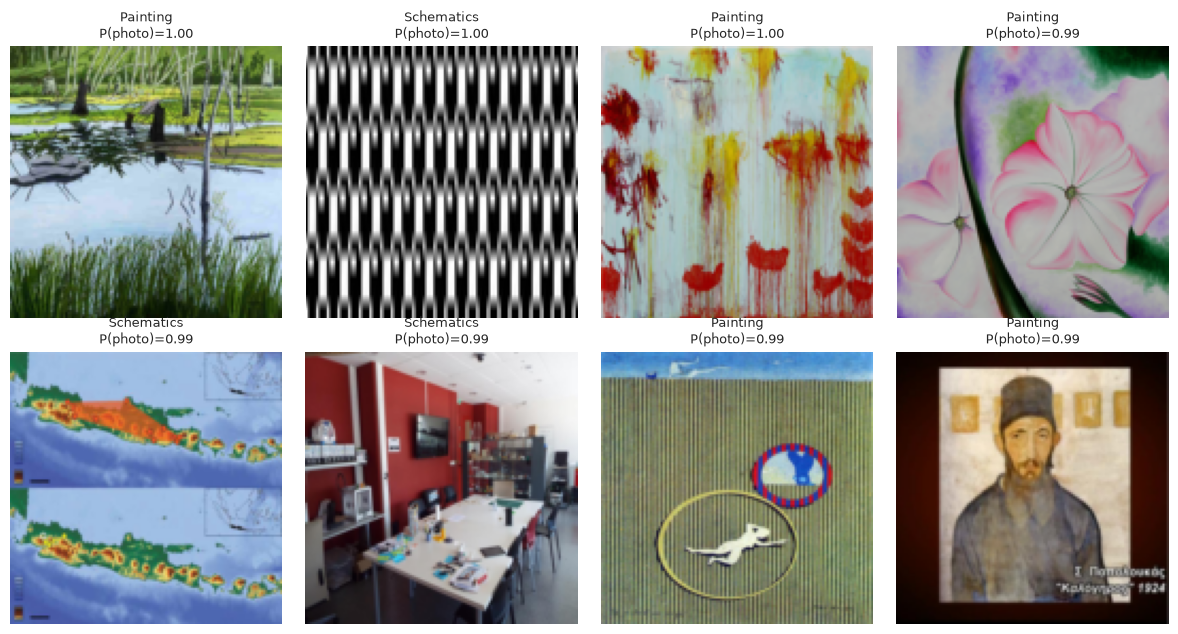

In [29]:
fig = evaluation.show_errors(Xe, me, probas["ext (réaliste)"], kind="fp", n=8)
if fig is None:
    print("Aucun faux positif sur le test étendu.")
else:
    plt.show()

**Faux négatifs** : des photos rejetées (les plus « sûres d'elles » d'abord).

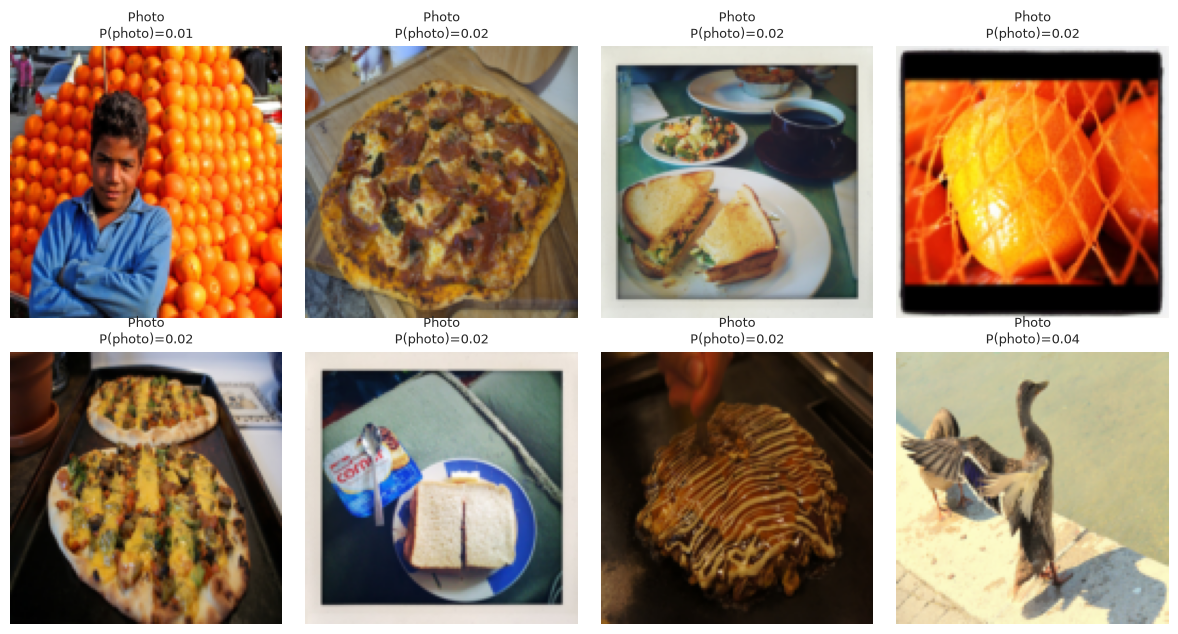

In [30]:
fig = evaluation.show_errors(Xe, me, probas["ext (réaliste)"], kind="fn", n=8)
if fig is None:
    print("Aucun faux négatif sur le test étendu.")
else:
    plt.show()

### 9.2 Choix du seuil de décision
Le seuil 0,5 est un défaut. Pour TouNum, **laisser passer une non-photo** (faux positif, baisse de précision) et
**perdre une photo** (faux négatif, baisse du rappel) n'ont pas le même coût : le bon seuil est une décision
métier. Le tableau ci-dessous aide à le choisir sur le test étendu, où les photos sont minoritaires.

,précision,rappel,F1,faux positifs,faux négatifs
seuil,,,,,
0.1,0.560,0.986,0.714,774,14
0.3,0.687,0.936,0.793,426,64
0.5,0.758,0.881,0.815,281,119
0.7,0.815,0.801,0.808,182,199
0.9,0.873,0.606,0.715,88,394


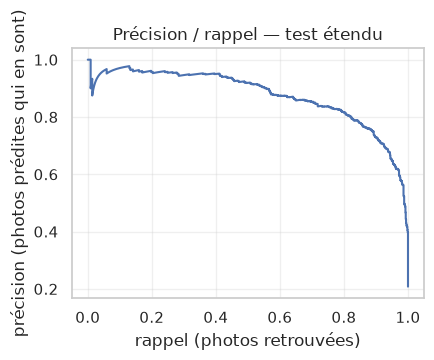

In [31]:
rows = []
for thr in (0.1, 0.3, 0.5, 0.7, 0.9):
    r = evaluation.evaluate_binary(ye, probas["ext (réaliste)"], threshold=thr)
    rows.append({"seuil": thr, "précision": r["precision"], "rappel": r["recall"], "F1": r["f1"],
                 "faux positifs": r["fp"], "faux négatifs": r["fn"]})
display(pd.DataFrame(rows).set_index("seuil"))
evaluation.plot_precision_recall(ye, probas["ext (réaliste)"], "Précision / rappel — test étendu")
plt.show()

In [32]:
res_t, res_e = results["test (équilibré)"], results["ext (réaliste)"]
worst = per_src_ext.iloc[0]
display(Markdown(
    f"**Lecture automatique.** Test équilibré : accuracy **{res_t['accuracy']:.3f}**, F1 **{res_t['f1']:.3f}**, "
    f"ROC-AUC **{res_t['roc_auc']:.3f}**. Test étendu (photos ≈ {ye.mean():.0%}) : accuracy **{res_e['accuracy']:.3f}**, "
    f"précision **{res_e['precision']:.3f}**, rappel **{res_e['recall']:.3f}**, F1 **{res_e['f1']:.3f}**. "
    f"Le type d'image le moins bien classé est **{worst['source']}** (accuracy {worst['accuracy']:.3f}). "
    + ("La précision est plus basse sur le test étendu car les photos y sont minoritaires : à taux de faux positifs égal, "
       "les faux positifs pèsent plus lourd face à moins de vrais positifs. C'est la métrique à surveiller en production."
       if res_e["precision"] < res_t["precision"] - 0.01
       else "La précision reste stable malgré le déséquilibre des classes du test étendu.")
))

**Lecture automatique.** Test équilibré : accuracy **0.909**, F1 **0.907**, ROC-AUC **0.971**. Test étendu (photos ≈ 21%) : accuracy **0.917**, précision **0.758**, rappel **0.881**, F1 **0.815**. Le type d'image le moins bien classé est **Painting** (accuracy 0.824). La précision est plus basse sur le test étendu car les photos y sont minoritaires : à taux de faux positifs égal, les faux positifs pèsent plus lourd face à moins de vrais positifs. C'est la métrique à surveiller en production.

### 9.3 Sauvegarde et utilisation en production
Le modèle contient son propre prétraitement (`Rescaling`) : il suffit de lui fournir des images 128×128×3 en `uint8`.
La fonction `data.load_image` fait la conversion (RGB + redimensionnement) depuis n'importe quel fichier jpg / png.

In [33]:
MODEL_PATH = config.PROJECT_ROOT / "models" / "cnn_photo_final.keras"
MODEL_PATH.parent.mkdir(exist_ok=True)
final_model.save(MODEL_PATH)
reloaded = keras.models.load_model(MODEL_PATH)
assert np.allclose(reloaded.predict(Xte[:32], verbose=0), final_model.predict(Xte[:32], verbose=0), atol=1e-5)
print(f"Modèle sauvegardé : {MODEL_PATH.relative_to(config.PROJECT_ROOT)} ({MODEL_PATH.stat().st_size / 1e6:.1f} Mo) — rechargement vérifié.")


def predict_photo(model, paths, threshold=0.5):
    """Classe des fichiers image : renvoie un DataFrame (fichier, P(photo), est_une_photo)."""
    batch = np.stack([data.load_image(p) for p in paths])
    proba = modeling.predict_proba(model, batch)
    return pd.DataFrame({"fichier": [Path(p).name for p in paths], "P(photo)": proba.round(3),
                         "est_une_photo": proba >= threshold})


demo = me.sample(8, random_state=config.SEED)
out = predict_photo(reloaded, demo["path"].tolist())
out["vérité"] = demo["source"].to_numpy()
display(out)

Modèle sauvegardé : models/cnn_photo_final.keras (1.4 Mo) — rechargement vérifié.


,fichier,P(photo),est_une_photo,vérité
0,painting_01890.jpg,0.083,False,Painting
1,schematics_05586.jpg,0.001,False,Schematics
2,photo_8162.jpg,0.977,True,Photo
3,painting_06269.jpg,0.081,False,Painting
4,photo_7444.jpg,0.983,True,Photo
5,painting_01896.jpg,0.058,False,Painting
6,painting_01208.jpg,0.131,False,Painting
7,photo_5365.jpg,0.518,True,Photo


## 10. Comparaison avec un réseau pré-entraîné (MobileNetV2)

Pour **justifier le choix d'architecture par les résultats**, on le compare à **MobileNetV2** pré-entraîné sur ImageNet
(1,4 million d'images), utilisé comme extracteur de caractéristiques **gelé** : seule la tête (`Dense` sigmoïde) est
entraînée. C'est le *transfert d'apprentissage*. Les poids sont téléchargés depuis Internet à la première utilisation.

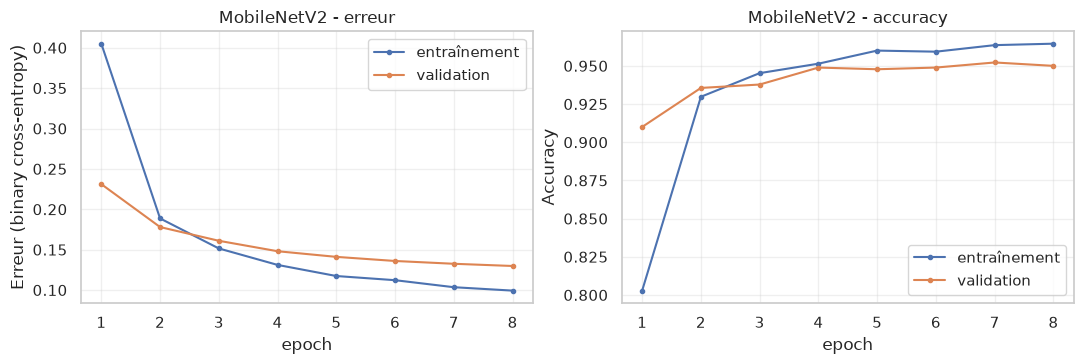

,paramètres,entraînables,test accuracy,test F1,test AUC,ext accuracy,ext F1,ext AUC,ext acc. Painting,durée d'entraînement (s)
modèle,,,,,,,,,,
CNN maison (+ early stopping),106481,106001,0.909,0.907,0.971,0.917,0.815,0.968,0.824,215
MobileNetV2 gelé + tête,2259265,1281,0.954,0.955,0.986,0.957,0.902,0.992,0.882,58


In [34]:
def summarize(model, name):
    row = {"modèle": name, "paramètres": model.count_params(),
           "entraînables": int(sum(np.prod(w.shape) for w in model.trainable_weights))}
    for label, (Xs, ys, ms) in {"test": (Xte, yte, mte), "ext": (Xe, ye, me)}.items():
        p = modeling.predict_proba(model, Xs)
        r = evaluation.evaluate_binary(ys, p)
        row[f"{label} accuracy"], row[f"{label} F1"], row[f"{label} AUC"] = r["accuracy"], r["f1"], r["roc_auc"]
        if label == "ext":
            acc = evaluation.per_source_accuracy(ms, p).set_index("source")["accuracy"]
            row["ext acc. Painting"] = acc.get("Painting", np.nan)
    return row


compare_rows = [summarize(final_model, f"CNN maison ({best_name})")]
try:
    mnet = modeling.build_mobilenet()
    keras.utils.set_random_seed(config.SEED)
    t0 = time.perf_counter()
    mnet_hist = modeling.train(mnet, data.make_dataset(Xtr, ytr, shuffle=True), data.make_dataset(Xva, yva),
                               epochs=EPOCHS["mobilenet"], class_weight=data.class_weights(ytr), verbose=0)
    mnet_sec = time.perf_counter() - t0
    row = summarize(mnet, "MobileNetV2 gelé + tête")
    row["durée d'entraînement (s)"] = round(mnet_sec)
    compare_rows.append(row)
    evaluation.plot_history(mnet_hist, "MobileNetV2")
    plt.show()
except Exception as exc:  # pas de réseau pour télécharger les poids ImageNet, par exemple
    print(f"Comparaison MobileNetV2 ignorée : {type(exc).__name__}: {exc}")
compare_rows[0]["durée d'entraînement (s)"] = round(imp_df.loc[best_name, "durée (s)"])
compare_df = pd.DataFrame(compare_rows).set_index("modèle")
display(compare_df)

In [35]:
if len(compare_df) == 2:
    a, b = compare_df.iloc[0], compare_df.iloc[1]
    gain = b["ext accuracy"] - a["ext accuracy"]
    ratio = b["paramètres"] / a["paramètres"]
    if gain > 0.02:
        verdict = (f"MobileNetV2 est nettement plus précis (+{gain:.3f} d'accuracy sur le test étendu) avec {ratio:.0f} fois plus "
                   "de paramètres. Si TouNum accepte un modèle plus lourd et la dépendance à des poids pré-entraînés, c'est le "
                   "meilleur candidat pour la production ; le CNN maison reste une base légère, autonome et entièrement maîtrisée.")
    elif gain < -0.02:
        verdict = (f"Le CNN maison fait mieux (+{-gain:.3f} d'accuracy sur le test étendu) avec {ratio:.0f} fois moins de "
                   "paramètres : il est retenu.")
    else:
        verdict = ("Performances comparables (écart < 0,02) : le CNN maison, plus léger et autonome, suffit.")
    display(Markdown(
        f"**Lecture automatique.** CNN maison : {int(a['paramètres']):,} paramètres, accuracy test {a['test accuracy']:.3f} / "
        f"ext {a['ext accuracy']:.3f}, peintures {a['ext acc. Painting']:.3f}. MobileNetV2 : {int(b['paramètres']):,} "
        f"paramètres ({int(b['entraînables']):,} entraînables), accuracy test {b['test accuracy']:.3f} / "
        f"ext {b['ext accuracy']:.3f}, peintures {b['ext acc. Painting']:.3f}. **{verdict}**"
    ))

**Lecture automatique.** CNN maison : 106,481 paramètres, accuracy test 0.909 / ext 0.917, peintures 0.824. MobileNetV2 : 2,259,265 paramètres (1,281 entraînables), accuracy test 0.954 / ext 0.957, peintures 0.882. **MobileNetV2 est nettement plus précis (+0.040 d'accuracy sur le test étendu) avec 21 fois plus de paramètres. Si TouNum accepte un modèle plus lourd et la dépendance à des poids pré-entraînés, c'est le meilleur candidat pour la production ; le CNN maison reste une base légère, autonome et entièrement maîtrisée.**

## 11. Conclusion, limites et suites

### Ce qui a été réalisé
1. Un **workflow reproductible de la donnée brute au modèle** : inventaire des archives, échantillonnage disjoint,
   extraction sélective, normalisation (RGB, 128×128), cache, découpage stratifié.
2. Un **CNN de ≈ 106 k paramètres** entraîné par Adam sur l'entropie croisée binaire, validé par une progression
   de difficulté croissante (section 4), et comparé à un réseau pré-entraîné (section 10, dont la conclusion
   indique quel modèle retenir en production).
3. Une **analyse biais/variance** chiffrée (sections 6 à 8) et une comparaison de techniques de régularisation.
4. Une **évaluation honnête** sur un jeu de test jamais utilisé, équilibré et réaliste (section 9), avec analyse des
   erreurs et choix du seuil.
5. Un **modèle sauvegardé** (`models/cnn_photo_final.keras`) et une fonction d'inférence (`predict_photo`).

### Limites et esprit critique
- **Échantillon** : 6 000 images de modélisation sur ~42 000 disponibles ; les performances sur la totalité pourraient
  être légèrement meilleures. Les effectifs se règlent dans `config.py`.
- **Résolution 128×128 et étirement** : on perd les détails fins (utiles pour distinguer une peinture réaliste d'une
  photo) et on déforme les pages allongées.
- **Définition de « photo »** : l'étiquette dépend de l'archive d'origine. Une peinture hyper-réaliste ou une photo
  fortement retouchée reste ambiguë, y compris pour un humain ; des erreurs d'étiquetage dans les archives plafonnent
  l'accuracy atteignable.
- **Généralisation** : le modèle est évalué sur des images de même provenance. Des images venant d'autres
  sources (scanners différents, autres types de documents, autres époques) peuvent dégrader les résultats.
- **Qualité d'image** : toutes les images d'entraînement sont de qualité correcte. Le livrable 2 (débruitage) devra
  vérifier que le filtre reste performant sur des images bruitées ou floues.
- **Reproductibilité** : de petites variations numériques sont possibles d'une machine à l'autre.

### Pistes pour la suite
- Entraîner sur la totalité des archives et à plus haute résolution (GPU) ;
- affiner les peintures réalistes (augmentation ciblée, *fine-tuning* de MobileNetV2) ;
- ajuster le seuil avec TouNum selon le coût d'une erreur (section 9.2) ;
- **brancher ce filtre en amont du prétraitement et du captioning** (livrables 2 et 3) et mesurer son effet de bout en bout ;
- mettre en place un suivi en production (part de photos prédites, échantillon relu à la main) pour détecter une dérive des données.